# ESE5023 Assignment 3

In [1]:
# Import modules

import numpy as np
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
%matplotlib inline

# Month names, used for panel titles and axis ticks
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Coastline segments from Natural Earth 110m, stored as one array with a NaN row between segments. cartopy didnot work anyway on my laptop, so the maps use plain lat-lon axes and the coastlines are drawn by hand.
try:
    coast = np.load("coastlines.npz")["coast"]
except FileNotFoundError:
    coast = None

def draw_coast(ax):
    # Coastlines on a plain longitude-latitude axis, drawn twice so that the 0-360 and -180-180 conventions are both covered
    if coast is not None:
        ax.plot(coast[:, 0], coast[:, 1], color="0.3", linewidth=0.5)
        ax.plot(coast[:, 0] + 360, coast[:, 1], color="0.3", linewidth=0.5)

## 1. Global methane levels from 2002

`200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc` contains monthly averaged
column methane (`xch4`) on a 5°×5° grid from 2003-01 to 2020-06.

In [2]:
# Open the methane file
ch4 = xr.open_dataset("200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc", engine="netcdf4")

# Missing retrievals are written as 1e20 in this file and flagged by the missing_value attribute. Mask them out by hand as well, so the arithmetic does not depend on the attribute being decoded.
xch4 = ch4["xch4"].where(ch4["xch4"] < 1e-3)

# xch4 is stored in mole/mole in this file, convert it to ppb
xch4 = xch4 * 1e9
xch4.attrs["units"] = "ppb"

# Check the dimensions and the unit
print(xch4.dims, xch4.shape)
print("units:", xch4.attrs["units"])

('time', 'lat', 'lon') (210, 36, 72)
units: ppb


### 1.1 Methane climatology for each month

In [3]:
# Climatology of each calendar month, i.e. average all Januaries, Februaries, ...
xch4_clim = xch4.groupby("time.month").mean(dim="time")

# Grid cells with less than 6 months of data are too noisy to average, mask them out
xch4_clim = xch4_clim.where(xch4.notnull().sum(dim="time") >= 6)

# Month names for the panel titles
xch4_clim = xch4_clim.assign_coords(month=month_names)

# One map per month
print(xch4_clim.shape)

(12, 36, 72)


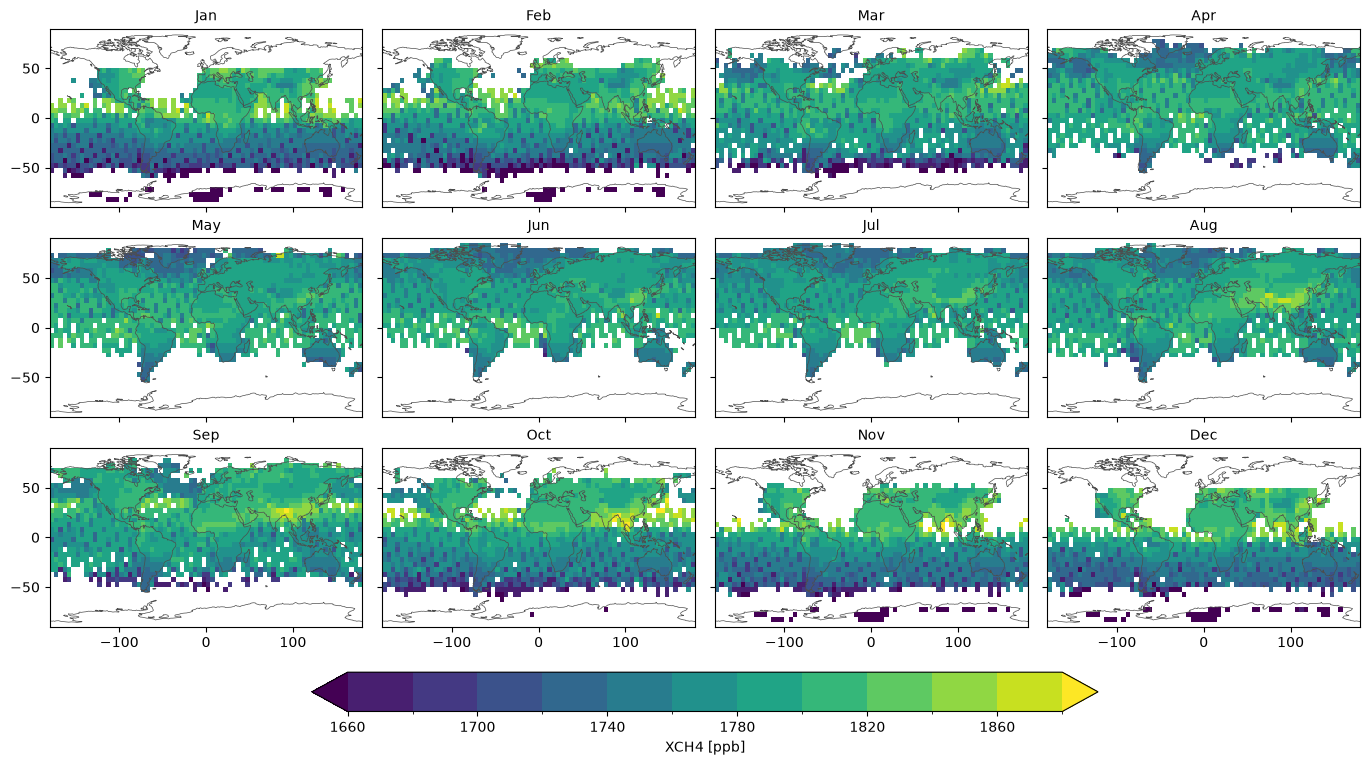

In [4]:
# 12 panels, one per month, all with the same color scale
fg = xch4_clim.plot(col="month", col_wrap=4, figsize=(14, 8.5),
                    levels=np.arange(1660, 1881, 20), cmap="viridis", extend="both",
                    cbar_kwargs={"orientation": "horizontal", "shrink": 0.6,
                                 "pad": 0.06, "label": "XCH4 [ppb]"})
fg.set_titles("{value}")

# Coastlines for every panel, the axis labels are only kept on the outer edges
for ax in fg.axs.flat:
    draw_coast(ax)
    ax.set_xlabel("")
    ax.set_ylabel("")

fg.fig.savefig("figs/fig1_1.png", dpi=200, bbox_inches="tight")
plt.show()

The climatology is higher in the Northern Hemisphere (about 1810-1850 ppb) than in the
Southern Hemisphere (about 1660-1760 ppb). Most methane sources (wetlands, rice fields, ruminants and
fossil fuel use) are on land north of the equator, and the inter-hemispheric mixing time is about one
year, so the gradient is maintained. The seasonal cycle is clearest over northern mid-latitudes, where
XCH4 peaks in July-September (wetland emission in the warm season) and reaches its minimum in spring.
Over the southern high latitudes the values are lowest and several cells are missing, because the
satellite retrievals there are sparse or fail over bright and cloudy scenes.

### 1.2 Globally averaged methane

In [5]:
# Area of a 5x5 grid cell is proportional to cos(lat), so use cos(lat) as weight
weights = np.cos(np.deg2rad(xch4.lat))

# Global mean, cells with missing data are skipped
xch4_global = xch4.weighted(weights).mean(dim=["lat", "lon"])

# Linear trend over the whole period
t = (xch4_global.time.dt.year + (xch4_global.time.dt.month - 1) / 12).where(xch4_global.notnull())
slope = np.polyfit(t.dropna("time"), xch4_global.dropna("time"), 1)[0]
print(f"Linear trend: {slope:.2f} ppb/yr")

Linear trend: 6.44 ppb/yr


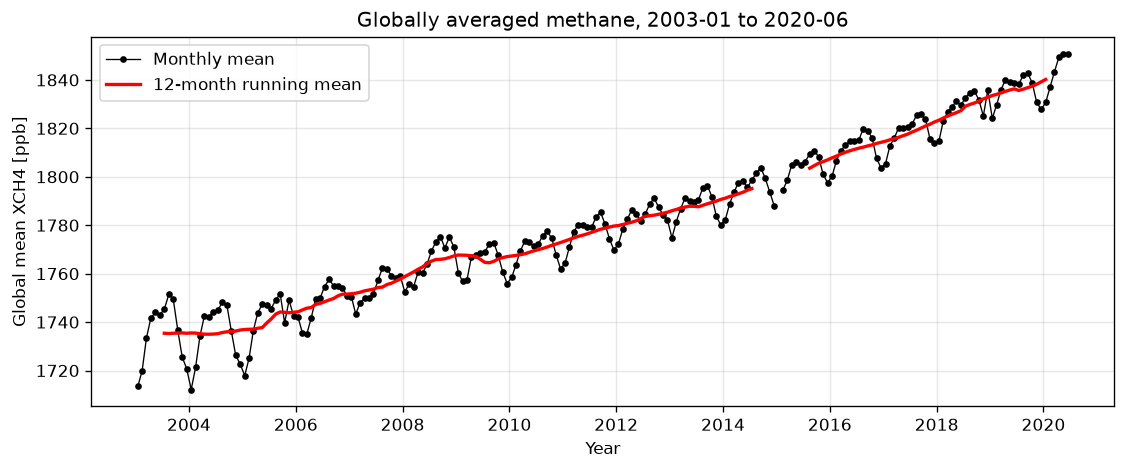

In [6]:
fig, ax = plt.subplots(figsize=(11, 4), dpi=120)

# Monthly values and the 12-month running mean
ax.plot(xch4_global.time, xch4_global, "o-", color="k", markersize=3, linewidth=0.8,
        label="Monthly mean")
ax.plot(xch4_global.time, xch4_global.rolling(time=12, center=True).mean(),
        color="r", linewidth=2, label="12-month running mean")

ax.set(xlabel="Year", ylabel="Global mean XCH4 [ppb]",
       title="Globally averaged methane, 2003-01 to 2020-06")
ax.grid(alpha=0.3)
ax.legend()

plt.savefig("figs/fig1_2.png", bbox_inches="tight")
plt.show()

The global mean XCH4 rises from about 1715 ppb in early 2003 to about 1850 ppb in June
2020, an increase of roughly 110 ppb with a linear trend of 6.4 ppb/yr. The rise is not steady:
2003-2006 is almost flat with a small decrease around 2004, the curve climbs again from 2007, and the
increase accelerates after 2014. On top of the trend there is an annual cycle of about 25 ppb,
lowest in January (1761.6 ppb) and highest in April-May (1787.3 ppb) with a second peak in August,
which comes from the seasonal cycle of wetland emissions and of the OH sink. The month-to-month wiggles of a few ppb follow interannual
changes in wetland emissions and the satellite sampling; January 2015 has no data at all. The shape
of the curve agrees with the NASA SVS methane time series.

### 1.3 Deseasonalized methane at [15°S, 150°W]

In [7]:
# Grid point closest to [15S, 150W]; longitude in this file runs from -180 to 180
xch4_pt = xch4.sel(lat=-15, lon=-150, method="nearest")
print("grid point:", float(xch4_pt.lat), float(xch4_pt.lon))
print("missing months:", int(xch4_pt.isnull().sum()))

# Clouds and retrieval failures leave gaps, fill them by linear interpolation in time
xch4_pt = xch4_pt.interpolate_na(dim="time", method="linear")

# Subtract the climatology of the same calendar month to remove the seasonal cycle
xch4_pt_anom = xch4_pt.groupby("time.month") - xch4_pt.groupby("time.month").mean(dim="time")

grid point: -12.5 -147.5
missing months: 133


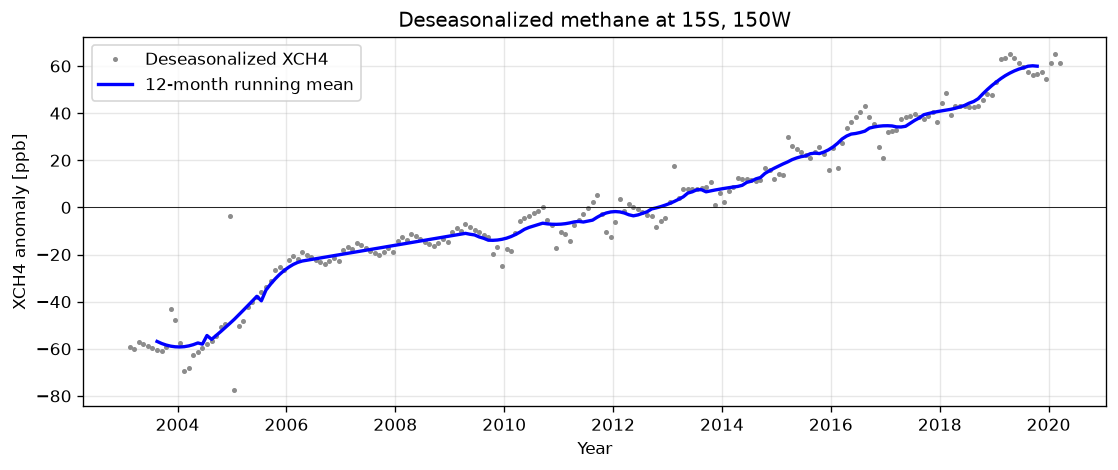

In [8]:
fig, ax = plt.subplots(figsize=(11, 4), dpi=120)

ax.plot(xch4_pt_anom.time, xch4_pt_anom, ".", color="0.55", markersize=4,
        label="Deseasonalized XCH4")
ax.plot(xch4_pt_anom.time, xch4_pt_anom.rolling(time=12, center=True).mean(),
        color="b", linewidth=2, label="12-month running mean")
ax.axhline(0, color="k", linewidth=0.5)

ax.set(xlabel="Year", ylabel="XCH4 anomaly [ppb]",
       title="Deseasonalized methane at 15S, 150W")
ax.grid(alpha=0.3)
ax.legend()

plt.savefig("figs/fig1_3.png", bbox_inches="tight")
plt.show()

At this point in the tropical South Pacific the seasonal amplitude is small, so the
deseasonalized curve nearly follows the trend: the anomaly grows from about -60 ppb in 2003 to
+60 ppb in 2019, the same 110-120 ppb increase as the global mean, with a slope of about 6.5 ppb/yr.
The 12-month running mean is flat in 2009-2011 and slows down around 2013-2014. The remaining
month-to-month scatter of about ±15 ppb is retrieval noise. Two thirds of the months at this single
grid cell have no retrieval (persistent cloud over the warm pool), so the gaps are filled by
interpolation and the short-term wiggles should not be over-interpreted.

## 2. Niño 3.4 index

`NOAA_NCDC_ERSST_v3b_SST.nc` contains monthly SST on a 2°×2° grid from 1960 to 2016. The Niño 3.4
region is 5°S-5°N, 170°W-120°W.

In [9]:
# Open the SST file
sst_ds = xr.open_dataset("NOAA_NCDC_ERSST_v3b_SST.nc", engine="netcdf4")

# Land points are filled with -999, mask them even if the attribute is not decoded
sst = sst_ds["sst"].where(sst_ds["sst"] > -100)

# Niño 3.4 region; longitude here runs 0-360, so 170W is 190E and 120W is 240E
nino34 = sst.sel(lat=slice(-5, 5), lon=slice(190, 240))
nino34

<xarray.DataArray 'sst' (time: 684, lat: 5, lon: 26)> Size: 356kB
array([[[28.17175 , 28.048628, 27.931675, ..., 25.335768, 25.169556,
         25.033987],
        [27.653809, 27.508678, 27.380558, ..., 24.529833, 24.379114,
         24.262102],
        [27.294712, 27.152628, 27.040548, ..., 24.302225, 24.20406 ,
         24.110378],
        [27.31989 , 27.21504 , 27.137045, ..., 25.115402, 25.088928,
         25.041584],
        [27.475496, 27.433014, 27.394337, ..., 26.195345, 26.237955,
         26.236437]],

       [[28.002878, 27.878937, 27.77678 , ..., 25.838228, 25.72304 ,
         25.661585],
        [27.38209 , 27.24077 , 27.128601, ..., 25.093372, 24.979416,
         24.945719],
        [26.918188, 26.775816, 26.672338, ..., 24.87573 , 24.817144,
         24.791187],
        [26.900671, 26.78532 , 26.706003, ..., 25.566336, 25.587357,
         25.581785],
        [27.096472, 27.03789 , 26.985928, ..., 26.423603, 26.4975  ,
...
         24.638456],
        [27.4362  , 27.216879, 27.008093, ..., 23.697813, 23.6218  ,
         23.572655],
        [26.943743, 26.713234, 26.503487, ..., 23.393393, 23.317305,
         23.257576],
        [27.244932, 27.02486 , 26.828966, ..., 24.460382, 24.387613,
         24.339931],
        [28.00594 , 27.82021 , 27.642656, ..., 25.809574, 25.781157,
         25.78427 ]],

       [[28.438414, 28.248383, 28.045935, ..., 25.008183, 24.926899,
         24.863983],
        [27.542393, 27.319422, 27.089153, ..., 23.975195, 23.925642,
         23.895918],
        [27.013718, 26.767624, 26.530039, ..., 23.649809, 23.623123,
         23.61405 ],
        [27.204172, 26.961138, 26.734722, ..., 24.61257 , 24.585806,
         24.587051],
        [27.795042, 27.592173, 27.39842 , ..., 25.878181, 25.872791,
         25.903019]]], shape=(684, 5, 26), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
  * lat      (lat) float32 20B -4.0 -2.0 0.0 2.0 4.0
  * lon      (lon) float32 104B 190.0 192.0 194.0 196.0 ... 236.0 238.0 240.0
Attributes:
    pointwidth:          1.0
    valid_min:           -3.0
    valid_max:           45.0
    units:               degree_Celsius
    long_name:           Extended reconstructed sea surface temperature
    standard_name:       sea_surface_temperature
    iridl:hasSemantics:  iridl:SeaSurfaceTemperature

### 2.1 Monthly climatology and anomalies

In [10]:
# Monthly climatology of the Niño 3.4 SST
nino34_clim = nino34.groupby("time.month").mean(dim="time")

# Anomaly = SST minus the climatology of the same calendar month
nino34_anom = nino34.groupby("time.month") - nino34_clim

# Average over the box to get the index
nino34_index = nino34_anom.mean(dim=["lat", "lon"])

# 3-month running mean, as used for the operational ONI
nino34_index_3m = nino34_index.rolling(time=3, center=True).mean()

print("box mean climatology:", float(nino34_clim.mean()))

box mean climatology: 27.035411834716797


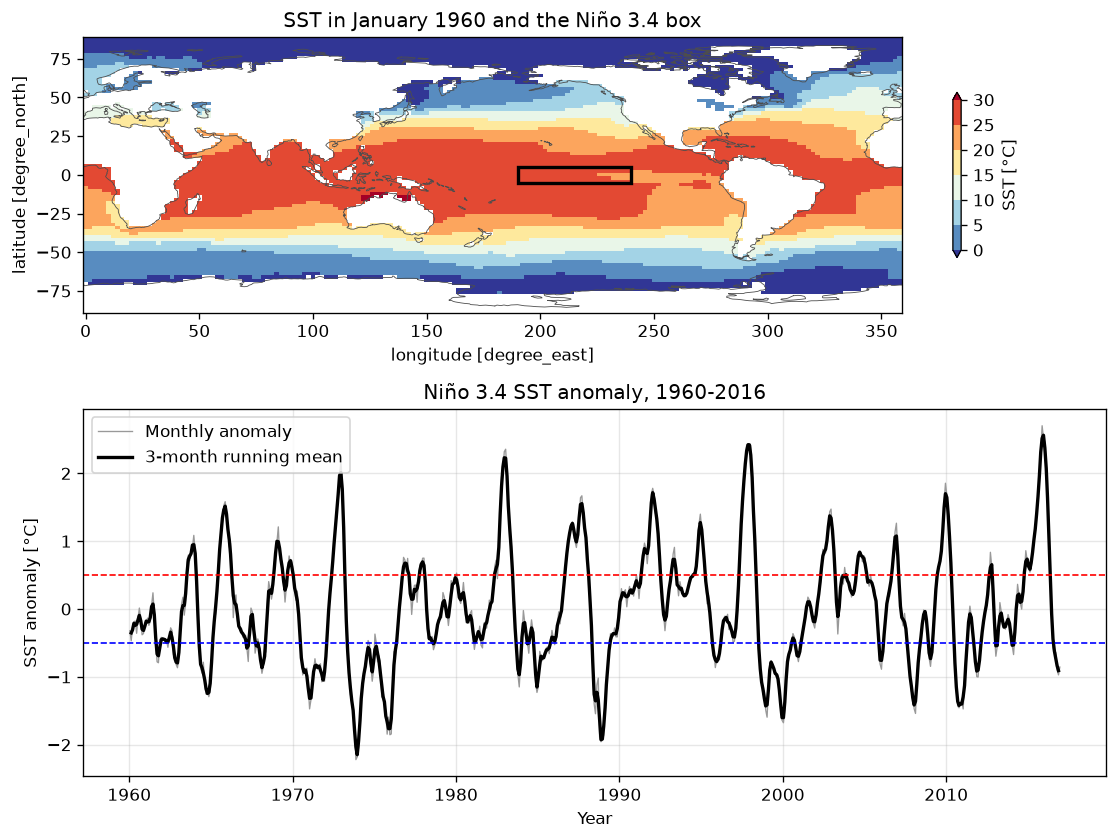

In [11]:
fig = plt.figure(figsize=(11, 8), dpi=120)
grid = plt.GridSpec(2, 1, height_ratios=[1.2, 1.6], hspace=0.3)

# Map of the region
ax = fig.add_subplot(grid[0])
sst.isel(time=0).plot(ax=ax, cmap="RdYlBu_r",
                      levels=np.arange(0, 31, 5), extend="both",
                      cbar_kwargs={"label": "SST [°C]", "shrink": 0.6})
draw_coast(ax)
ax.add_patch(plt.Rectangle((190, -5), 50, 10, fill=False, edgecolor="k",
                           linewidth=2))
ax.set_title("SST in January 1960 and the Niño 3.4 box")

# Index
ax = fig.add_subplot(grid[1])
ax.plot(nino34_index.time, nino34_index, color="0.6", linewidth=0.8,
        label="Monthly anomaly")
ax.plot(nino34_index_3m.time, nino34_index_3m, color="k", linewidth=2,
        label="3-month running mean")
ax.axhline(0.5, color="r", linestyle="--", linewidth=1)
ax.axhline(-0.5, color="b", linestyle="--", linewidth=1)
ax.set(xlabel="Year", ylabel="SST anomaly [°C]",
       title="Niño 3.4 SST anomaly, 1960-2016")
ax.grid(alpha=0.3)
ax.legend(loc="upper left")

plt.savefig("figs/fig2_1.png", bbox_inches="tight")
plt.show()

The climatology of the box is about 27.0 °C. The anomalies oscillate between about
-1.5 and +1.5 °C, and the 3-month running mean reaches +2.7 °C in 1997-1998 and +2.4 °C in
2015-2016 (strong El Niño) and -2.2 °C in 1973-1974 and 1988-1989 (strong La Niña). Warm and cold
phases last one to two years and alternate irregularly with a period of about 3-7 years.

### 2.2 Visualizing the Niño 3.4 index

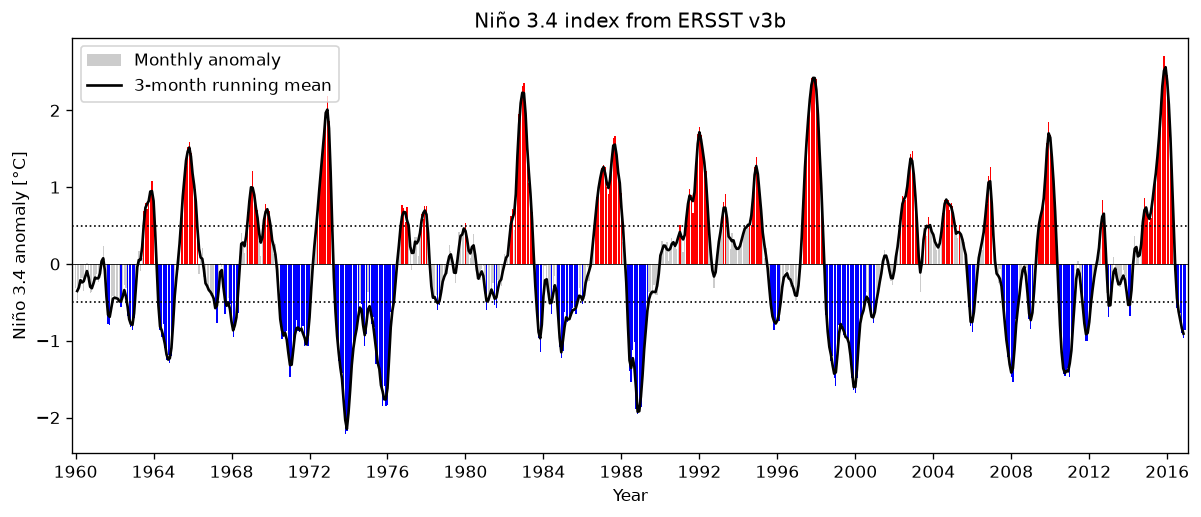

In [12]:
fig, ax = plt.subplots(figsize=(12, 4.5), dpi=120)

# Bars are red for El Niño (>0.5°C), blue for La Niña (<-0.5°C), grey in between
colors = np.where(nino34_index >= 0.5, "r", np.where(nino34_index <= -0.5, "b", "0.8"))
ax.bar(np.arange(nino34_index.size), nino34_index, color=colors, width=0.8)

# 3-month running mean
ax.plot(np.arange(nino34_index.size), nino34_index_3m, color="k", linewidth=1.6,
        label="3-month running mean")

# Thresholds
ax.axhline(0.5, color="k", linestyle=":", linewidth=1)
ax.axhline(-0.5, color="k", linestyle=":", linewidth=1)
ax.axhline(0, color="k", linewidth=0.5)

# One tick every 4 years, at January
years = nino34_index.time.dt.year.values
months = nino34_index.time.dt.month.values
ticks = [i for i in range(nino34_index.size) if months[i] == 1 and years[i] % 4 == 0]
ax.set_xticks(ticks)
ax.set_xticklabels(years[ticks])

ax.set(xlabel="Year", ylabel="Niño 3.4 anomaly [°C]",
       title="Niño 3.4 index from ERSST v3b")

# Legend with proxy handles, the bars are colored one by one
handles = [Patch(facecolor="0.8", label="Monthly anomaly"),
           Line2D([], [], color="k", linewidth=1.6, label="3-month running mean")]
ax.legend(handles=handles, loc="upper left")
ax.set_xlim(-2, nino34_index.size + 1)

plt.savefig("figs/fig2_2.png", bbox_inches="tight")
plt.show()

The plot follows the NOAA monitoring figure: monthly anomalies as bars, the
3-month running mean as a black line, and the ±0.5 °C thresholds as dotted lines. Red bars mark
El Niño months and blue bars La Niña months, so an event is a run of at least 5 months beyond the
threshold. The record shows the well-known warm events of 1972-73, 1982-83, 1987-88, 1991-92,
1997-98 (the strongest), 2002-03, 2009-10 and 2015-16, and cold events such as 1973-74, 1988-89,
1998-99, 2010-11 and 2011-12. The 3-month running mean is slightly smoother and a little weaker than
the individual monthly peaks.

## 3. Exploring a netCDF dataset

The dataset used here is the GPCP monthly precipitation product (NASA GSFC, GES DISC product
`GPCPMON`, version 2.3). It gives monthly precipitation rate in mm/day on a 2.5°×2.5° global grid
from 1979 to the present, merged from rain gauges and several satellite estimates. The file
`precip.mon.mean.nc` has already been downloaded from the NOAA PSL mirror of the same product and is
read from the local folder here.

In [13]:
# Open the local GPCP file, no download needed time_bnds contains fill values that break the automatic time decoding, so it is dropped
precip_ds = xr.open_dataset("precip.mon.mean.nc", engine="netcdf4", drop_variables=["time_bnds"])

# Missing cells are filled with -9.96921e36, mask them by hand as well
precip = precip_ds["precip"].where(precip_ds["precip"] >= 0)
precip

<xarray.DataArray 'precip' (time: 570, lat: 72, lon: 144)> Size: 24MB
array([[[0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        [0.        , 0.        , 0.        , ..., 0.        ,
         0.        , 0.        ],
        ...,
        [0.9812404 , 0.9320181 , 0.8138066 , ..., 0.91615057,
         0.811867  , 0.9017285 ],
        [0.7499759 , 0.77453935, 0.67079806, ..., 0.6945452 ,
         0.73984015, 0.7661884 ],
        [0.6614727 , 0.5773457 , 0.617506  , ..., 0.5728163 ,
         0.6059005 , 0.70766836]],

       [[0.33657596, 0.31659493, 0.32447177, ..., 0.2847315 ,
         0.29603544, 0.3030814 ],
        [0.2571579 , 0.28121045, 0.28316426, ..., 0.25939476,
         0.25399455, 0.27813244],
        [0.08254394, 0.10533275, 0.07907505, ..., 0.17585263,
         0.19220772, 0.1084968 ],
...
        [0.5216847 , 0.49534613, 0.4748505 , ..., 0.5826817 ,
         0.5659768 , 0.54213786],
        [0.36788887, 0.36925232, 0.36117464, ..., 0.35354304,
         0.35446122, 0.3595948 ],
        [0.44303966, 0.43291026, 0.42471036, ..., 0.45927274,
         0.45774105, 0.4554742 ]],

       [[0.9382158 , 0.93175846, 0.91930497, ..., 0.954314  ,
         0.928406  , 0.9279937 ],
        [0.30641642, 0.3017029 , 0.30120537, ..., 0.35339564,
         0.33360094, 0.32394877],
        [0.14655498, 0.13502593, 0.12311004, ..., 0.19954681,
         0.19133282, 0.17417893],
        ...,
        [1.2882973 , 1.3032465 , 1.3176882 , ..., 1.1190826 ,
         1.1731389 , 1.228416  ],
        [1.3118677 , 1.3079515 , 1.3127191 , ..., 1.2995148 ,
         1.303173  , 1.3132905 ],
        [1.1599952 , 1.14306   , 1.10651   , ..., 1.1801817 ,
         1.1706793 , 1.1683509 ]]], shape=(570, 72, 144), dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1979-01-01 1979-02-01 ... 2026-06-01
  * lat      (lat) float32 288B -88.75 -86.25 -83.75 ... 83.75 86.25 88.75
  * lon      (lon) float32 576B 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
Attributes:
    long_name:     Average Monthly Rate of Precipitation
    valid_range:   [  0. 100.]
    units:         mm/day
    precision:     32767
    var_desc:      Precipitation
    dataset:       GPCP Version 2.3 Combined Precipitation Dataset
    level_desc:    Surface
    statistic:     Mean
    parent_stat:   Mean
    actual_range:  [ 0.       47.327435]

### 3.1 Time series with the seasonal cycle removed

In [14]:
# Area weighting and the global mean
weights = np.cos(np.deg2rad(precip.lat))
precip_global = precip.weighted(weights).mean(dim=["lat", "lon"])

# Remove the monthly climatology
precip_clim = precip_global.groupby("time.month").mean(dim="time")
precip_anom = precip_global.groupby("time.month") - precip_clim

print("global mean:", float(precip_global.mean()), "mm/day")
print("anomaly range:", float(precip_anom.min()), float(precip_anom.max()))

global mean: 2.6876349449157715 mm/day
anomaly range: -0.1788182258605957 0.1288754940032959


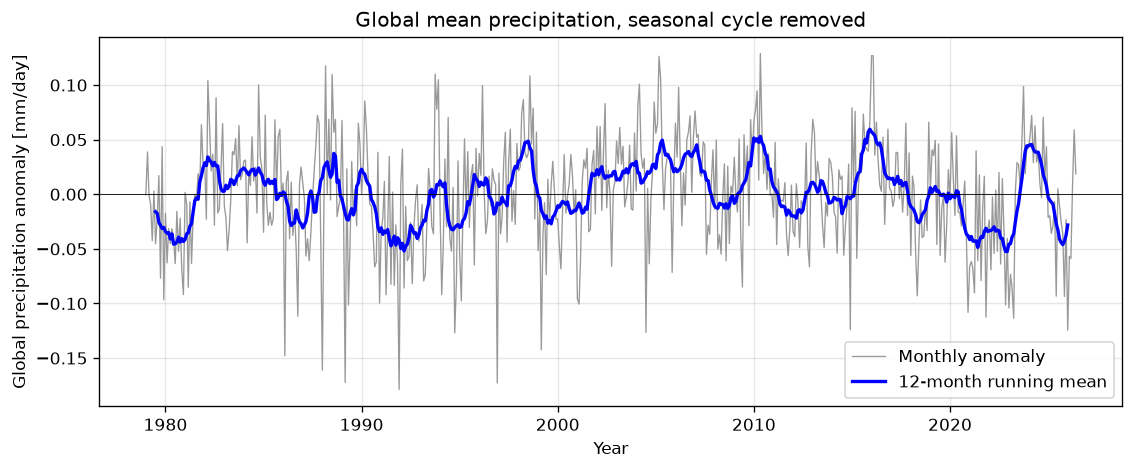

In [15]:
fig, ax = plt.subplots(figsize=(11, 4), dpi=120)

ax.plot(precip_anom.time, precip_anom, color="0.6", linewidth=0.8,
        label="Monthly anomaly")
ax.plot(precip_anom.time, precip_anom.rolling(time=12, center=True).mean(),
        color="b", linewidth=2, label="12-month running mean")
ax.axhline(0, color="k", linewidth=0.5)

ax.set(xlabel="Year", ylabel="Global precipitation anomaly [mm/day]",
       title="Global mean precipitation, seasonal cycle removed")
ax.grid(alpha=0.3)
ax.legend()

plt.savefig("figs/fig3_1.png", bbox_inches="tight")
plt.show()

The global mean precipitation is 2.69 mm/day and its seasonal cycle is weak
(the climatology stays within 2.63-2.72 mm/day), because the ITCZ rain belt simply moves from one
hemisphere to the other. After removing the monthly climatology the anomalies are only ±0.18 mm/day,
but the El Niño years stand out: 1982-83, 1987-88, 1991-92, 1997-98 and 2015-16 are positive because
the warm pool rain shifts into the central Pacific, and the two years after Pinatubo (1991-1993) are
negative. There is no clear long-term trend at the global scale over this period.

### 3.2 Five more plots

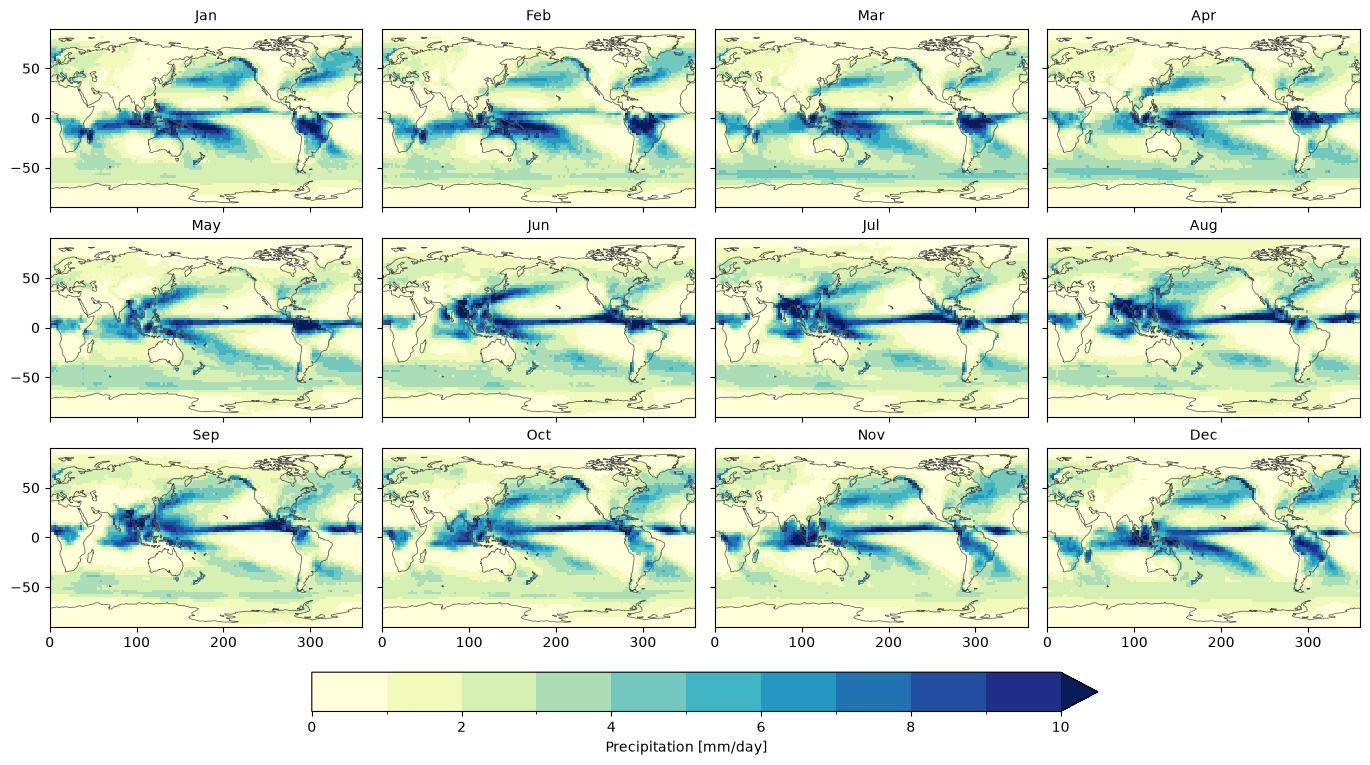

In [16]:
# (1) Monthly climatology of precipitation
precip_month_clim = precip.groupby("time.month").mean(dim="time")
precip_month_clim = precip_month_clim.assign_coords(month=month_names)

fg = precip_month_clim.plot(col="month", col_wrap=4, figsize=(14, 8.5),
                            levels=np.arange(0, 10.1, 1), cmap="YlGnBu", extend="max",
                            cbar_kwargs={"orientation": "horizontal", "shrink": 0.6,
                                         "pad": 0.06, "label": "Precipitation [mm/day]"})
fg.set_titles("{value}")
for ax in fg.axs.flat:
    draw_coast(ax)
    ax.set_xlabel("")
    ax.set_ylabel("")

fg.fig.savefig("figs/fig3_2a.png", dpi=180, bbox_inches="tight")
plt.show()

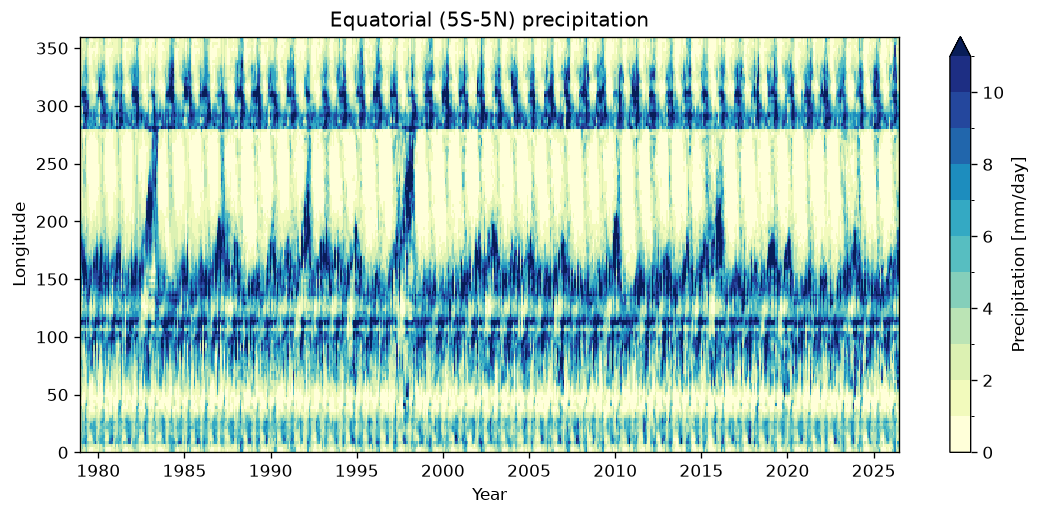

In [17]:
# (2) Hovmoeller diagram: longitude against time, averaged over 5S-5N
fig, ax = plt.subplots(figsize=(11, 4.5), dpi=120)

precip.sel(lat=slice(-5, 5)).mean(dim="lat").plot(ax=ax, x="time", y="lon",
                                                  cmap="YlGnBu",
                                                  levels=np.arange(0, 12, 1), extend="max",
                                                  cbar_kwargs={"label": "Precipitation [mm/day]"})
ax.set(xlabel="Year", ylabel="Longitude", title="Equatorial (5S-5N) precipitation")

plt.savefig("figs/fig3_2b.png", bbox_inches="tight")
plt.show()

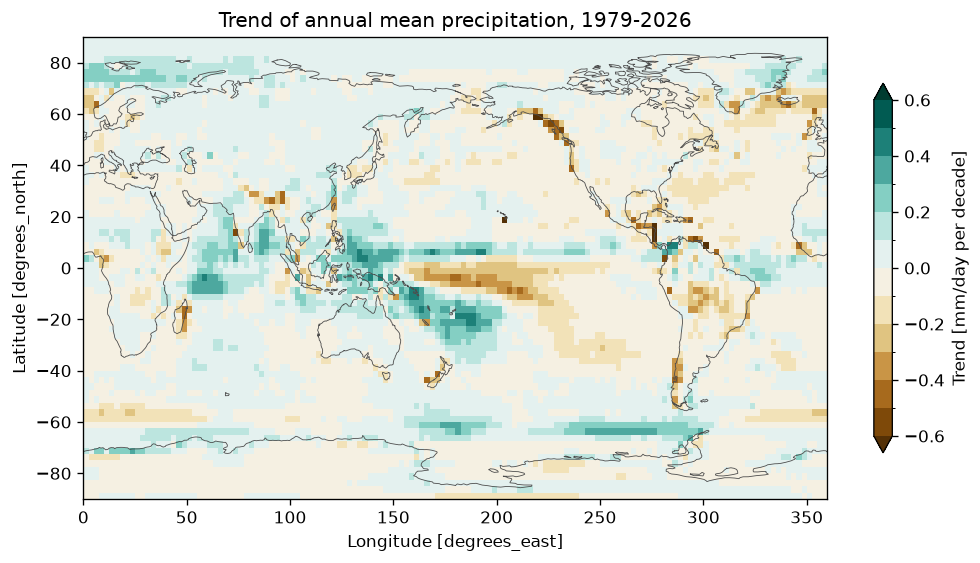

In [18]:
# (3) Trend of annual mean precipitation, mm/day per decade
precip_year = precip.resample(time="1YE").mean(dim="time")
t_year = precip_year.time.dt.year + 0.5

trend = precip_year.assign_coords(time=t_year).polyfit(dim="time", deg=1)
trend_slope = trend["polyfit_coefficients"].sel(degree=1) * 10

fig = plt.figure(figsize=(10, 5), dpi=120)
ax = fig.add_subplot()
trend_slope.plot(ax=ax, cmap="BrBG",
                 levels=np.arange(-0.6, 0.65, 0.1), extend="both",
                 cbar_kwargs={"label": "Trend [mm/day per decade]", "shrink": 0.8})
draw_coast(ax)
ax.set_title("Trend of annual mean precipitation, 1979-2026")

plt.savefig("figs/fig3_2c.png", bbox_inches="tight")
plt.show()

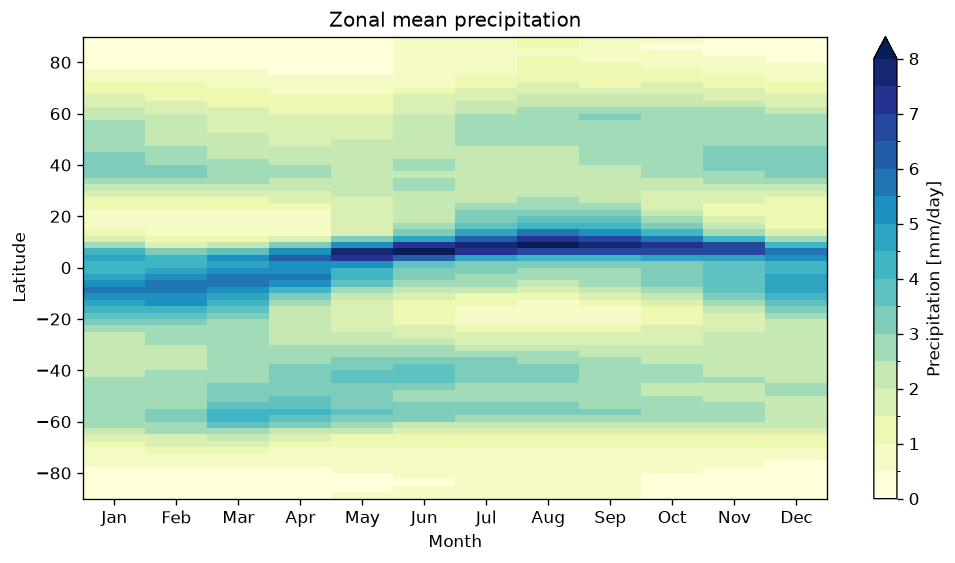

In [19]:
# (4) Zonal mean seasonal cycle, latitude against month
zonal = precip.mean(dim="lon").groupby("time.month").mean(dim="time")

fig, ax = plt.subplots(figsize=(10, 5), dpi=120)
zonal.plot(ax=ax, x="month", y="lat", cmap="YlGnBu", levels=np.arange(0, 8.1, 0.5),
           extend="max", cbar_kwargs={"label": "Precipitation [mm/day]"})
ax.set(xlabel="Month", ylabel="Latitude", title="Zonal mean precipitation")
ax.set_xticks(np.arange(1, 13))
ax.set_xticklabels(month_names)

plt.savefig("figs/fig3_2d.png", bbox_inches="tight")
plt.show()

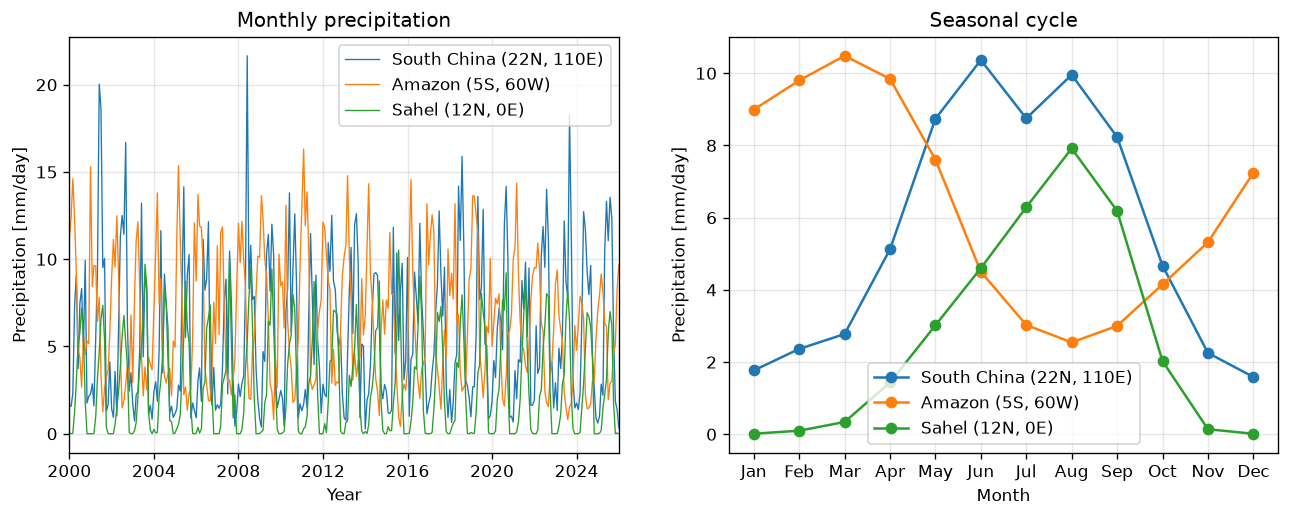

In [20]:
# (5) Three regions: monthly series and seasonal cycle
# Longitude follows the 0-360 convention of this file, so 60W is 300E
regions = {"South China (22N, 110E)": (22, 110),
           "Amazon (5S, 60W)": (-5, 300),
           "Sahel (12N, 0E)": (12, 0)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=120)

for name, (lat, lon) in regions.items():
    series = precip.sel(lat=lat, lon=lon, method="nearest")
    axes[0].plot(series.time, series, linewidth=0.8, label=name)
    axes[1].plot(np.arange(1, 13), series.groupby("time.month").mean(dim="time"),
                 marker="o", label=name)

axes[0].set(xlabel="Year", ylabel="Precipitation [mm/day]", title="Monthly precipitation")
axes[0].set_xlim(np.datetime64("2000-01-01"), np.datetime64("2026-01-01"))
axes[1].set(xlabel="Month", ylabel="Precipitation [mm/day]", title="Seasonal cycle")
axes[1].set_xticks(np.arange(1, 13))
axes[1].set_xticklabels(month_names)
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

plt.savefig("figs/fig3_2e.png", bbox_inches="tight")
plt.show()

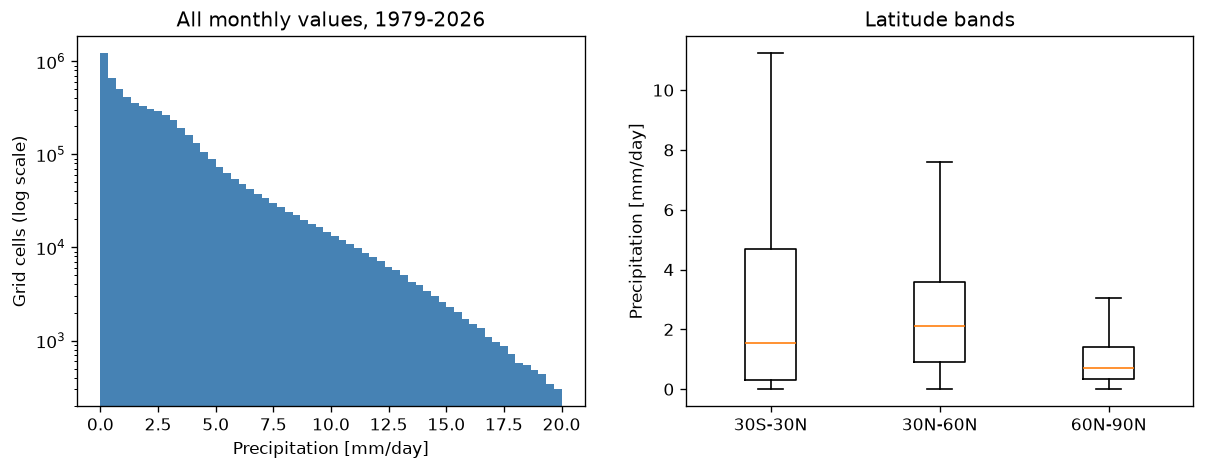

In [21]:
# (6) Distribution of the monthly values
fig, axes = plt.subplots(1, 2, figsize=(12, 4), dpi=120)

values = precip.values[~np.isnan(precip.values)]
axes[0].hist(values, bins=60, range=(0, 20), color="steelblue")
axes[0].set_yscale("log")
axes[0].set(xlabel="Precipitation [mm/day]", ylabel="Grid cells (log scale)",
            title="All monthly values, 1979-2026")

# Latitude bands
axes[1].boxplot([precip.sel(lat=slice(-30, 30)).values.ravel(),
                 precip.sel(lat=slice(30, 60)).values.ravel(),
                 precip.sel(lat=slice(60, 90)).values.ravel()],
                tick_labels=["30S-30N", "30N-60N", "60N-90N"], showfliers=False)
axes[1].set(ylabel="Precipitation [mm/day]", title="Latitude bands")

plt.savefig("figs/fig3_2f.png", bbox_inches="tight")
plt.show()

The six plots use the same file in six ways. The 12-panel climatology (3.2a) shows
the seasonal migration of the rain belts: the ITCZ, the Asian monsoon from June to September, the
Amazon wet season from December to April and the dry zone over North Africa. The Hovmöller diagram
(3.2b) follows the equatorial rain bands in longitude and time, including the eastward shift of
convection into the central Pacific during the strong 1997-98 El Niño. The trend map (3.2c) shows
drying over the tropical South Pacific, the Mediterranean and parts of South America, and wetting at
high northern latitudes and over the equatorial Pacific, with values between -0.6 and +0.5 mm/day per
decade. The zonal mean against month (3.2d) puts the ITCZ near 5-10°S in February-March and near
10°N in July-August. The regional panels (3.2e) compare the South China monsoon (peak in June), the
Amazon (peak in March-April) and the Sahel (single peak in August), and show the year-to-year
differences. The histograms and box plots (3.2f) give the distribution of the values and confirm that
tropical latitudes are much wetter and more variable than high latitudes.